# Autoencoders for outlier detection
**Data Centric AI – Outlier detection** · Master Degree in Computer Science

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/Autoencoder_outlier_detection.ipynb)

This notebook reproduces the example of the slides *Example: a Dataset with Outliers* … *Colab Code: the Key Steps*:

* dataset generation and plots;
* the autoencoder 2 → 32 → 16 → **1** → 16 → 32 → 2 (tanh) and its training curves;
* the decoding of the latent space (the learned manifold);
* metrics and detection plots.

A final section shows the two main weaknesses listed in *Autoencoders: Pros and Cons*: a **too large bottleneck** and **contaminated training data**.

Runs on CPU in about 2–3 minutes (one minute for the main example). Results may differ slightly from the slides with a different TensorFlow version.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

SEED = 7
NORM_C, OUT_C, FP_C = '#4C78A8', '#C0392B', '#E67E22'
print('TensorFlow', tf.__version__)

I0000 00:00:1792563386.943329     186 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792563387.857690     186 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. A dataset with outliers
* 1000 normal points along a curved band: x₂ = 1.5 sin(x₁) + Gaussian noise (σ = 0.15)
* 40 outliers scattered far from the band (distance > 0.8 along x₂), but **inside the range of each feature**: a per-feature statistical test would miss most of them.

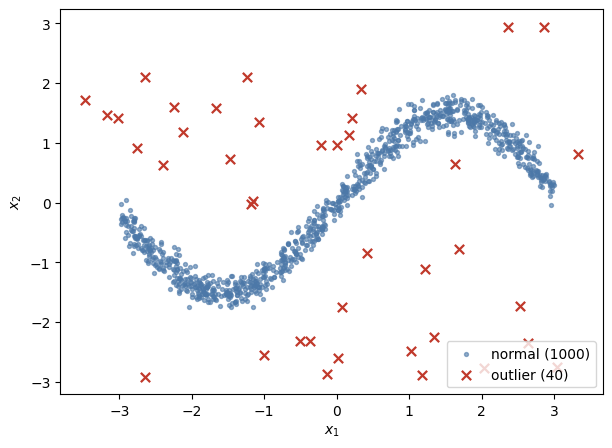

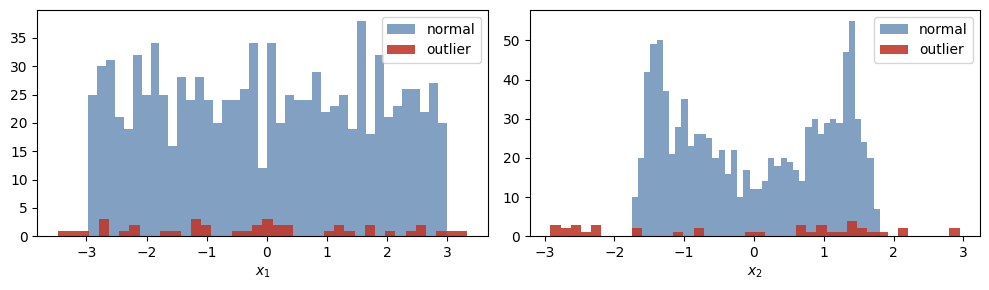

In [2]:
rng = np.random.default_rng(SEED)

def make_outliers(m, rng):
    out = []
    while len(out) < m:
        p = np.array([rng.uniform(-3.5, 3.5), rng.uniform(-3, 3)])
        if abs(p[1] - 1.5 * np.sin(p[0])) > 0.8:      # far from the band
            out.append(p)
    return np.array(out)

x1 = rng.uniform(-3, 3, 1000)
X_normal = np.c_[x1, 1.5 * np.sin(x1) + rng.normal(0, 0.15, 1000)]
X_out = make_outliers(40, rng)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(*X_normal.T, s=8, c=NORM_C, alpha=.6, label='normal (1000)')
ax.scatter(*X_out.T, marker='x', c=OUT_C, s=45, lw=1.6, label='outlier (40)')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.legend(loc='lower right'); plt.show()

# per-feature view: the outliers are not extreme on any single feature
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for j, ax in enumerate(axes):
    ax.hist(X_normal[:, j], bins=40, color=NORM_C, alpha=.7, label='normal')
    ax.hist(X_out[:, j], bins=40, color=OUT_C, alpha=.9, label='outlier'); ax.set_xlabel(f'$x_{j+1}$'); ax.legend()
plt.tight_layout(); plt.show()

## 2. Semi-supervised protocol
* Training: 700 normal points only
* Test: 300 unseen normal points + 40 outliers

In [3]:
perm = rng.permutation(1000)
X_train = X_normal[perm[:700]]
X_test = np.vstack([X_normal[perm[700:]], X_out])
y_test = np.r_[np.zeros(300), np.ones(40)].astype(int)

# 1. Train on NORMAL data only (semi-supervised)
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

## 3. The autoencoder 2 → 32 → 16 → [1] → 16 → 32 → 2
Hidden layers use tanh; bottleneck and output are linear. The bottleneck of size 1 forces each point to be described by a single number: its position along the curve.

In [4]:
def build_ae(bottleneck=1, seed=SEED):
    keras.utils.set_random_seed(seed)
    inp  = keras.Input(shape=(2,))
    h    = layers.Dense(32, activation='tanh')(inp)
    h    = layers.Dense(16, activation='tanh')(h)
    code = layers.Dense(bottleneck, name='bottleneck')(h)
    h    = layers.Dense(16, activation='tanh')(code)
    h    = layers.Dense(32, activation='tanh')(h)
    out  = layers.Dense(2)(h)
    ae = keras.Model(inp, out)
    ae.compile(optimizer='adam', loss='mse')
    return ae

ae = build_ae()
ae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 1)              │            17 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,283 (5.01 KB)

 Trainable params: 1,283 (5.01 KB)

 Non-trainable params: 0 (0.00 B)

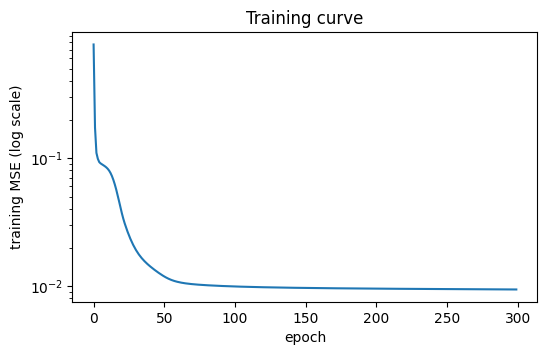

final training loss: 0.009405383840203285


In [5]:
hist = ae.fit(Xtr, Xtr, epochs=300, batch_size=32, verbose=0)   # target = input
plt.figure(figsize=(6, 3.5)); plt.semilogy(hist.history['loss'])
plt.xlabel('epoch'); plt.ylabel('training MSE (log scale)'); plt.title('Training curve'); plt.show()
print('final training loss:', hist.history['loss'][-1])

## 4. The learned manifold
Decoding all the values of the 1-D code gives the curve learned by the AE. Each input is mapped (approximately projected) onto it: normal points move a little, outliers move a lot.

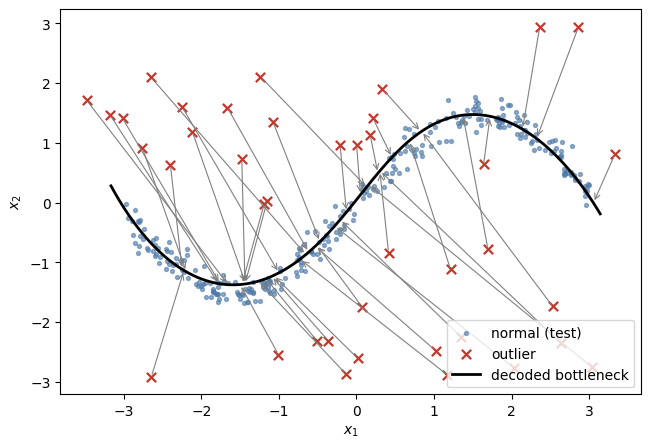

In [6]:
encoder = keras.Model(ae.input, ae.get_layer('bottleneck').output)
dec_in = keras.Input(shape=(1,)); h = dec_in
for layer in ae.layers[ae.layers.index(ae.get_layer('bottleneck')) + 1:]:
    h = layer(h)
decoder = keras.Model(dec_in, h)

z_tr = encoder.predict(Xtr, verbose=0)
z_grid = np.linspace(z_tr.min() - .3, z_tr.max() + .3, 400)[:, None]
curve = scaler.inverse_transform(decoder.predict(z_grid, verbose=0))
rec_te = scaler.inverse_transform(ae.predict(Xte, verbose=0))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(*X_test[y_test == 0].T, s=8, c=NORM_C, alpha=.6, label='normal (test)')
ax.scatter(*X_test[y_test == 1].T, marker='x', c=OUT_C, s=45, lw=1.6, label='outlier')
for a, b in zip(X_test[y_test == 1], rec_te[y_test == 1]):
    ax.annotate('', b, a, arrowprops=dict(arrowstyle='->', color='gray', lw=.8))
ax.plot(*curve.T, 'k', lw=2, label='decoded bottleneck')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.legend(loc='lower right'); plt.show()

## 5. Anomaly score and detection
Anomaly score = reconstruction error; threshold = 99th percentile of the errors on the training data.

In [7]:
# 3. Anomaly score = reconstruction error
err_tr = np.mean((Xtr - ae.predict(Xtr, verbose=0))**2, axis=1)
err_te = np.mean((Xte - ae.predict(Xte, verbose=0))**2, axis=1)

# 4. Threshold on the training errors
t = np.percentile(err_tr, 99)
y_pred = (err_te > t).astype(int)                # 1 = outlier

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'TP = {tp}  FP = {fp}  FN = {fn}  TN = {tn}')
print(f'Precision = {precision_score(y_test, y_pred):.2f}  Recall = {recall_score(y_test, y_pred):.2f}  '
      f'F1 = {f1_score(y_test, y_pred):.2f}  ROC AUC = {roc_auc_score(y_test, err_te):.2f}')

TP = 40  FP = 6  FN = 0  TN = 294
Precision = 0.87  Recall = 1.00  F1 = 0.93  ROC AUC = 1.00


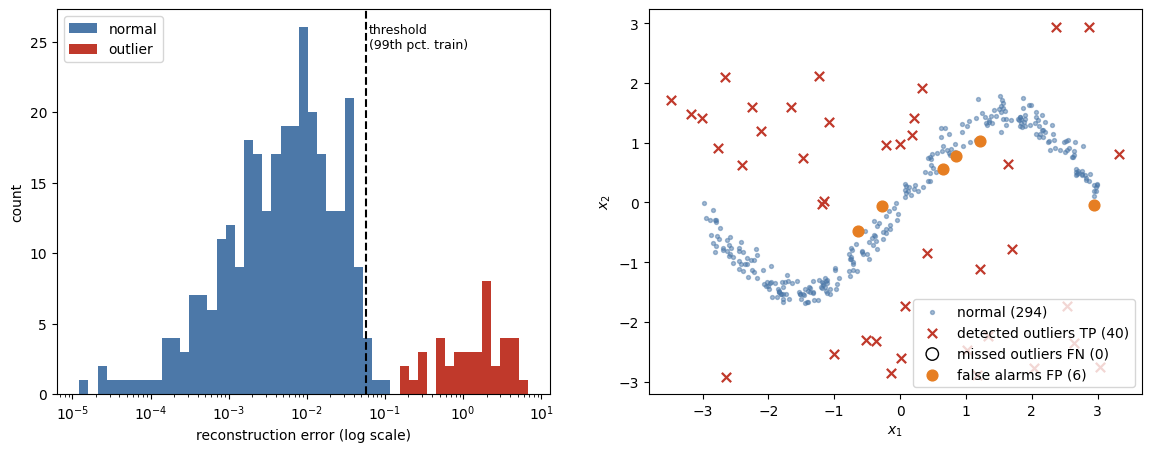

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bins = np.logspace(np.log10(err_te.min()) - .1, np.log10(err_te.max()) + .1, 50)
ax1.hist(err_te[y_test == 0], bins=bins, color=NORM_C, label='normal')
ax1.hist(err_te[y_test == 1], bins=bins, color=OUT_C, label='outlier')
ax1.axvline(t, ls='--', c='k'); ax1.text(t * 1.1, 0.9, 'threshold\n(99th pct. train)', transform=ax1.get_xaxis_transform(), fontsize=9)
ax1.set_xscale('log'); ax1.set_xlabel('reconstruction error (log scale)'); ax1.set_ylabel('count'); ax1.legend(loc='upper left')

n_ok = (y_test == 0) & (y_pred == 0); fpm = (y_test == 0) & (y_pred == 1)
ax2.scatter(*X_test[n_ok].T, s=8, c=NORM_C, alpha=.5, label=f'normal ({n_ok.sum()})')
ax2.scatter(*X_test[(y_test == 1) & (y_pred == 1)].T, marker='x', c=OUT_C, s=45, lw=1.6, label=f'detected outliers TP ({tp})')
ax2.scatter(*X_test[(y_test == 1) & (y_pred == 0)].T, facecolors='none', edgecolors='k', s=80, label=f'missed outliers FN ({fn})')
ax2.scatter(*X_test[fpm].T, c=FP_C, s=60, label=f'false alarms FP ({fp})')
ax2.set_xlabel('$x_1$'); ax2.set_ylabel('$x_2$'); ax2.legend(loc='lower right'); plt.show()

The false alarms are normal points in the noisy tails of the band (**swamping**): with a 99th-percentile threshold about 1% of the normal points are expected above it.

## 6. When the autoencoder fails
### 6.1 Bottleneck too large
With a bottleneck of size 2 (= input size) the AE can learn (an approximation of) the identity function and **reconstructs the outliers too**.

In [9]:
def run_experiment(X_fit, bottleneck=1):
    sc = StandardScaler().fit(X_fit)
    A, B = sc.transform(X_fit), sc.transform(X_test)
    m = build_ae(bottleneck); m.fit(A, A, epochs=300, batch_size=32, verbose=0)
    e_tr = np.mean((A - m.predict(A, verbose=0))**2, axis=1)
    e_te = np.mean((B - m.predict(B, verbose=0))**2, axis=1)
    pred = e_te > np.percentile(e_tr, 99)
    return {'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'ROC AUC': roc_auc_score(y_test, e_te)}

import pandas as pd
res = {'bottleneck = 1 (clean)': {'Precision': precision_score(y_test, y_pred), 'Recall': recall_score(y_test, y_pred),
                                  'F1': f1_score(y_test, y_pred), 'ROC AUC': roc_auc_score(y_test, err_te)}}
for b in [2, 8]:
    res[f'bottleneck = {b}'] = run_experiment(X_train, b)
pd.DataFrame(res).T.round(2)

,Precision,Recall,F1,ROC AUC
bottleneck = 1 (clean),0.87,1.00,0.93,1.00
bottleneck = 2,0.92,0.82,0.87,0.93
bottleneck = 8,0.92,0.90,0.91,0.99


### 6.2 Contaminated training data (unsupervised setting)
If the training set is not clean, the AE partly learns to reconstruct the outliers and – more important – the threshold computed on the training errors moves up: **masking**.

In [10]:
rng_c = np.random.default_rng(123)
for m in [35, 70]:          # 5% and 10% of contamination
    res[f'training + {m} outliers ({m / 700:.0%})'] = run_experiment(np.vstack([X_train, make_outliers(m, rng_c)]), 1)
table = pd.DataFrame(res).T.round(2); table

,Precision,Recall,F1,ROC AUC
bottleneck = 1 (clean),0.87,1.00,0.93,1.00
bottleneck = 2,0.92,0.82,0.87,0.93
bottleneck = 8,0.92,0.90,0.91,0.99
training + 35 outliers (5%),1.00,0.28,0.43,0.98
training + 70 outliers (10%),1.00,0.25,0.40,0.93


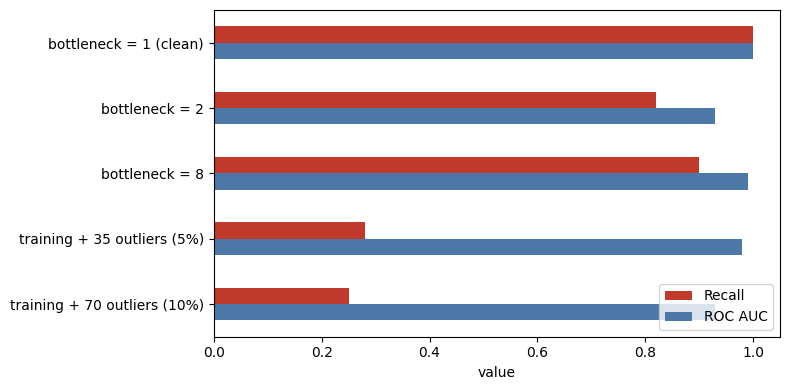

In [11]:
ax = table[['Recall', 'ROC AUC']].plot.barh(figsize=(8, 4), color=[OUT_C, NORM_C])
ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_xlabel('value'); plt.tight_layout(); plt.show()

* A larger bottleneck lowers the ROC AUC: the outliers are reconstructed better.
* With contamination the ROC AUC stays relatively high (the ranking is still informative) but the recall collapses: the threshold, computed on contaminated training errors, is too high.

## Takeaways
**Pros**: captures non-linear correlations (the curved band, where per-feature tests and axis-parallel methods struggle); needs only normal data; continuous score.

**Cons**: needs (almost) clean training data; the threshold and the bottleneck size are critical; architecture must be tuned; low interpretability.